# Step 4: Model 1 (short-term) with LightGBM

Model 1 scores every candidate in a slate. Its score is calibrated into **P1, a purchase probability**, in section 8b, and blended with Model 2 as `s = w·P1 + (1−w)·P2` in `step5_gate_and_evaluation.ipynb`. The final gate uses one weight, `w = 0.45`, for every user.

**Pipeline**
1. **Data:** the 17 final features. Training rows are the negative-sampled train slates (all positives + up to 20 negatives per slate).
2. **Objective:** binary classifier on *any interaction* with sample weights click 1 / cart 5 / purchase 10 (the `graded` objective from the ablation; interim report §2.2.5).
3. **Tuning:** Optuna (TPE sampler, median pruning). Learning rate fixed, number of trees by early stopping on val1. Each trial is scored with the per-slate NDCG@10 on val1 purchase slates.
4. **Guard against tuning to noise:** the top trials and the untuned ablation model are retrained with 3 seeds and compared with a paired bootstrap; the simplest configuration within noise of the best is chosen. Its 3 seed models form the final ensemble.
5. **Explainability:** gain importance and SHAP values on val1.
6. **Save:** the models, the chosen configuration and the raw ensemble scores for val2 and test.
7. **Calibration (section 8b):** Platt scaling of the raw score into P1 on val2, the same method as Model 2. The train searches with a purchase are also scored, for the final evaluation.
8. **Experiments (section 10, val1 only, nothing saved):** other training objectives, and performance by history length.

**Split use** (from `step1_data_preprocessing.ipynb`)
- `train`: fits the models.
- `val1`: early stopping, tuning and model choice. Scores reported on val1 are slightly optimistic because val1 was used for the choice.
- `val2`: **calibration only** (section 8b): Platt scaling of the score into P1, the same as Model 2. Not used for tuning or model choice. The gate (`step5_gate_and_evaluation.ipynb`) is also fitted on val2.
- `test`: **not used here.** Scored only, for the final evaluation of the Model 1 + Model 2 blend.

**Inputs:** `step2_model1/features_{train,val1,val2,test}.parquet` from `step2_model1_feature_engineering.ipynb`.

**Outputs** (in `step4_model1/`, not committed to git): `model1_seed{0,1,2}.txt`, `model1_config.json`, `calibration.json`, `model1_scores_val2.parquet`, `model1_scores_test.parquet`, `model1_scores_train.parquet`.

| File | What it is | Who uses it |
|---|---|---|
| `model1_seed0.txt`, `model1_seed1.txt`, `model1_seed2.txt` | The 3 trained LightGBM models: the chosen hyperparameters trained with 3 different random seeds, each saved at its early-stopped number of trees. Model 1's score is the average of their 3 raw (log-odds) outputs. | Anyone who needs to score new rows again. Load with `lgb.Booster(model_file=...)`. |
| `model1_config.json` | A small record of the model: the 17 features, chosen hyperparameters, winning Optuna trial, trees per seed, and the val1 NDCG@10 of the tuned and untuned models. | The report, and the next step, to know what the models are without opening this notebook. |
| `model1_scores_val2.parquet` | Model 1's score for every (slate, candidate) in val2: `slate_id`, `wid`, `label`, `raw_score`, and `p1` (calibrated purchase probability, added in section 8b). | The gate: fitted on val2. |
| `model1_scores_test.parquet` | The same for test (`p1` uses the val2 Platt formula). | Final evaluation: blend with Model 2 and evaluate once. |
| `model1_scores_train.parquet` | The same for the train slates with a purchase (negative-sampled lists, so optimistic). | The train rows of the final evaluation. |
| `calibration.json` | The Platt formula `P1 = sigmoid(a·raw_score + b)` fitted on val2: `a`, `b`. Same format as Model 2's. | The gate notebook, and anyone converting new raw scores into P1. |

**Run order:** after `step2_model1_feature_engineering.ipynb`. Restart the kernel, then run all cells top to bottom. The Optuna study is kept in memory, so a crash means rerunning from the start.

## 0. Setup

In [2]:
# Colab helper: optuna is not preinstalled on Colab (lightgbm, pyarrow and matplotlib are).
# Runs only on Colab and only if optuna is missing; does nothing locally.
import importlib.util
try:
    import google.colab
    if importlib.util.find_spec("optuna") is None:
        get_ipython().run_line_magic("pip", "install -q optuna")
except ImportError:              # not on Colab
    pass

In [ ]:
import os, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, pyarrow.parquet as pq
import lightgbm as lgb
import optuna
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)
warnings.filterwarnings("ignore", message="Overriding the parameters from Reference Dataset")   # harmless: val1 shares the training bins
pd.set_option("display.width", 200)

# Setup: on Colab, mount Google Drive (same project folder in every notebook).
# Locally, use the repo folder (the step folders next to this notebook).
try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/Grp8Submission")
except ImportError:              # not on Colab
    PROJECT = Path(".")
FEAT = PROJECT / "step2_model1"     # Model 1 features (from step 2)
OUT = PROJECT / "step4_model1"      # this notebook's outputs
OUT.mkdir(parents=True, exist_ok=True)

FINAL_FEATURES = [
    # context
    "current_query_length", "candidate_has_metadata",
    # popularity (log versions only)
    "candidate_log_popularity", "candidate_log_pop_cart", "candidate_log_pop_ord",
    # item history
    "item_click_cnt_7d", "item_cart_cnt_90d", "item_ord_cnt_365d",
    "item_days_since_cart", "item_days_since_ord",
    # brand history
    "brand_click_cnt_7d", "brand_cart_cnt_90d", "brand_ord_cnt_365d",
    "brand_days_since_cart", "brand_days_since_ord",
    # similarity
    "query_candidate_name_sim", "query_candidate_cate4_sim",
]
FEATURE_GROUP = {f: g for g, fs in {
    "context": FINAL_FEATURES[0:2], "popularity": FINAL_FEATURES[2:5], "item_history": FINAL_FEATURES[5:10],
    "brand_history": FINAL_FEATURES[10:15], "similarity": FINAL_FEATURES[15:17]}.items() for f in fs}

GRADED_WEIGHT = {0: 1.0, 1: 1.0, 2: 5.0, 3: 10.0}   # target = any interaction; click 1, cart 5, purchase 10
SEED = 42                       # Optuna sampler, sampling for SHAP, bootstrap
SEEDS = [0, 1, 2]               # model seeds for the re-check and the final ensemble
LEARNING_RATE = 0.05            # fixed; early stopping picks the number of trees
MAX_ROUNDS, EARLY_STOP = 5000, 100
N_TRIALS = 60                   # Optuna trials (completed + pruned)
TOP_K_RECHECK = 5               # best trials re-trained with 3 seeds
SHAP_ROWS = 200_000             # val1 rows sampled for SHAP values
THREADS = os.cpu_count() or 4

# untuned reference model from the ablation notebook (baseline for the tuning gain)
REFERENCE_PARAMS = dict(learning_rate=0.1, num_leaves=63, min_data_in_leaf=100,
                        feature_fraction=0.8, bagging_fraction=0.8, lambda_l2=1.0)

STUDY_NAME = "model1_lgbm_val1"
print("lightgbm", lgb.__version__, "| optuna", optuna.__version__, "| threads", THREADS)

lightgbm 4.7.0 | optuna 5.0.0 | threads 15


## 1. Load the features
Rows are sorted by slate so that each slate's candidates are contiguous (needed for LightGBM's query groups). The four splits are checked to share no slate.

In [4]:
def load(path, columns=None):
    # ignore_metadata avoids the pandas 2.x/3.x pyarrow-metadata TypeError
    return pq.read_table(path, columns=columns).to_pandas(ignore_metadata=True)


COLS = ["slate_id", "wid", "label"] + FINAL_FEATURES


def load_feats(split):
    path = FEAT / f"features_{split}.parquet"
    assert path.exists(), f"{path} not found: run step2_model1_feature_engineering.ipynb first"
    missing = [c for c in COLS if c not in pq.ParquetFile(path).schema_arrow.names]
    assert not missing, f"{split}: missing columns {missing}"
    f = load(path, columns=COLS)
    f["label"] = f["label"].astype(np.int8)
    return f.sort_values("slate_id", kind="stable").reset_index(drop=True)


fit = load_feats("train")       # "fit" because train() is the training function below
val1 = load_feats("val1")
val2 = load_feats("val2")       # scored only (section 6); labels are not used in this notebook
test = load_feats("test")       # scored only (section 6); labels are not used in this notebook

ids = {k: set(d["slate_id"].unique()) for k, d in {"train": fit, "val1": val1, "val2": val2, "test": test}.items()}
for a in ids:
    for b in ids:
        if a < b:
            assert not ids[a] & ids[b], f"slates shared between {a} and {b}"
print("no slate is shared between train, val1, val2 and test")

no slate is shared between train, val1, val2 and test


In [5]:
def purchase_slates(df):
    # rows of the slates that contain at least one purchase (the only slates the purchase metrics use)
    m = df["label"].eq(3).groupby(df["slate_id"]).transform("any").to_numpy()
    return df[m].reset_index(drop=True)


def slate_sizes(df):
    # candidates per slate, in row order (df must be sorted by slate)
    return df.groupby("slate_id", sort=False).size().to_numpy()


val1_p = purchase_slates(val1)

# label statistics for train and val1 only; val2 and test are left untouched
overview = pd.DataFrame({name: {
    "slates": d["slate_id"].nunique(), "rows": len(d), "rows_per_slate": len(d) / d["slate_id"].nunique(),
    "purchase_rate_%": 100 * d["label"].eq(3).mean(), "any_interaction_%": 100 * d["label"].ge(1).mean(),
    "purchase_slates": d.loc[d["label"].eq(3), "slate_id"].nunique()}
    for name, d in [("train (sampled)", fit), ("val1 (full)", val1)]}).T
print(overview.round(3).to_string())
print(f"\nval2: {val2['slate_id'].nunique():,} slates, {len(val2):,} rows | "
      f"test: {test['slate_id'].nunique():,} slates, {len(test):,} rows (scored only)")

                   slates       rows  rows_per_slate  purchase_rate_%  any_interaction_%  purchase_slates
train (sampled)  122083.0  2608369.0          21.366            0.566              8.651          14408.0
val1 (full)       17799.0  1589673.0          89.312            0.127              2.052           1945.0

val2: 16,924 slates, 1,511,179 rows | test: 17,025 slates, 1,500,706 rows (scored only)


## 2. Evaluation helpers
Per-slate metrics: the same code as section 9.6 of the feature notebook (NDCG@10, HitRate@10, HitRate@1, MRR; NaN scores rank last; ties broken at random and averaged over 5 orders). `paired_diff` bootstraps the mean per-slate difference between two scorers on the same slates.

In [6]:
METRICS = ["ndcg@10", "hit@10", "hit@1", "mrr"]


def _gains(label, relevance):
    label = np.asarray(label)
    if relevance == "purchase":
        return (label == 3).astype(np.float64)
    if relevance == "graded":
        return (2.0 ** label - 1.0).astype(np.float64)
    raise ValueError("relevance must be 'purchase' or 'graded'")


def _group_layout(sorted_slates):
    # start index of each slate block in an array sorted by slate, and the 1-based rank inside it
    n = len(sorted_slates)
    start = np.r_[0, np.flatnonzero(sorted_slates[1:] != sorted_slates[:-1]) + 1]
    size = np.diff(np.r_[start, n])
    rank = np.arange(n) - np.repeat(start, size) + 1
    return start, rank


def per_slate_metrics(df, score_col, k=10, relevance="purchase", higher_is_better=True, n_tiebreaks=5, seed=0):
    # one row per slate that has a relevant item, with ndcg@k, hit@k, hit@1, mrr
    slate = df["slate_id"].to_numpy()
    gain = _gains(df["label"].to_numpy(), relevance)
    has_rel = pd.Series(gain > 0).groupby(slate).transform("any").to_numpy()
    slate, gain = slate[has_rel], gain[has_rel]
    score = df[score_col].to_numpy(dtype=np.float64)[has_rel]
    if len(slate) == 0:
        raise ValueError("no slates with a relevant item")
    key = score if higher_is_better else -score
    key = np.where(np.isnan(key), -np.inf, key)
    ideal_order = np.lexsort((-gain, slate))
    start, rank = _group_layout(slate[ideal_order])
    disc = np.where(rank <= k, 1.0 / np.log2(rank + 1), 0.0)
    idcg = np.add.reduceat(gain[ideal_order] * disc, start)
    rng = np.random.default_rng(seed)
    acc = {m: np.zeros(len(start)) for m in METRICS}
    for _ in range(n_tiebreaks):
        tie = rng.random(len(slate))
        order = np.lexsort((tie, -key, slate))
        g = gain[order]
        rel = g > 0
        acc["ndcg@10"] += np.add.reduceat(g * disc, start) / idcg
        acc["hit@10"] += np.add.reduceat((rel & (rank <= k)).astype(float), start) > 0
        acc["hit@1"] += np.add.reduceat((rel & (rank == 1)).astype(float), start) > 0
        first = np.minimum.reduceat(np.where(rel, rank, np.inf), start)
        acc["mrr"] += 1.0 / first
    out = pd.DataFrame({m: v / n_tiebreaks for m, v in acc.items()})
    out = out.rename(columns={"ndcg@10": f"ndcg@{k}", "hit@10": f"hit@{k}"})
    out.insert(0, "slate_id", slate[ideal_order][start])
    return out


def summarize(per_slate, n_boot=1000, seed=0):
    # mean of each metric with a 95% bootstrap interval over slates
    rng = np.random.default_rng(seed)
    cols = [c for c in per_slate.columns if c != "slate_id"]
    vals = per_slate[cols].to_numpy()
    boot = vals[rng.integers(0, len(vals), size=(n_boot, len(vals)))].mean(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
    return pd.DataFrame({"mean": vals.mean(axis=0), "ci_low": lo, "ci_high": hi}, index=cols)


def paired_diff(a, b, col="ndcg@10", n_boot=2000, seed=0):
    # mean of a - b over the same slates, with a 95% bootstrap interval
    assert (a["slate_id"].to_numpy() == b["slate_id"].to_numpy()).all(), "slates not aligned"
    d = a[col].to_numpy() - b[col].to_numpy()
    rng = np.random.default_rng(seed)
    boot = d[rng.integers(0, len(d), size=(n_boot, len(d)))].mean(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return {"diff": d.mean(), "ci_low": lo, "ci_high": hi}


def seed_avg(tables):
    # average per-slate metrics over seeds (all tables cover the same slates in the same order)
    out = tables[0][["slate_id"]].copy()
    for t in tables[1:]:
        assert (t["slate_id"].to_numpy() == out["slate_id"].to_numpy()).all(), "slates not aligned"
    for m in METRICS:
        out[m] = np.mean([t[m].to_numpy() for t in tables], axis=0)
    return out


def self_test():
    # hand-checkable toy slates (same cases as the feature notebook)
    d = pd.DataFrame({"slate_id": [1, 1, 1, 2, 2, 3, 3], "label": [0, 3, 0, 3, 1, 0, 1],
                      "s": [0.9, 0.5, 0.1, 0.8, 0.2, 0.5, 0.4]})
    ps = per_slate_metrics(d, "s").set_index("slate_id")
    assert list(ps.index) == [1, 2]
    assert np.isclose(ps.loc[1, "ndcg@10"], 1 / np.log2(3)) and ps.loc[1, "mrr"] == 0.5 and ps.loc[1, "hit@1"] == 0
    assert (ps.loc[2] == 1).all()
    d2 = d.assign(s=[0.9, np.nan, 0.1, 0.8, 0.2, 0.5, 0.4])
    assert per_slate_metrics(d2, "s").set_index("slate_id").loc[1, "mrr"] == 1 / 3
    return True


assert self_test()
print("metric self-test OK")

metric self-test OK


## 3. Training setup
- **Target:** any interaction (label ≥ 1), with sample weights click 1, cart 5, purchase 10. Clicks and carts act as weaker positive signals, purchases count most.
- **Early stopping:** LightGBM's NDCG@10 on val1's purchase slates (purchase = relevant). The final score of each trial uses the notebook's own per-slate metric, so tuning and evaluation measure the same thing.
- The training `Dataset` is built once and reused by every trial. `feature_pre_filter=False` allows `min_data_in_leaf` to change between trials.
- No class-imbalance setting (`is_unbalance`, `scale_pos_weight`): negative sampling and the weights already rebalance, and the later Platt scaling on val2 restores the true purchase rate.

In [7]:
DATASET_PARAMS = {"feature_pre_filter": False, "verbose": -1}
BASE_PARAMS = {**DATASET_PARAMS, "objective": "binary", "bagging_freq": 1, "num_threads": THREADS,
               "deterministic": True, "force_row_wise": True, "metric": "ndcg", "eval_at": [10]}

y_fit = (fit["label"].to_numpy() >= 1).astype(np.int8)
w_fit = fit["label"].map(GRADED_WEIGHT).to_numpy(dtype=np.float64)
# group sizes are only needed because LightGBM's NDCG metric requires query information on every dataset
dtrain = lgb.Dataset(fit[FINAL_FEATURES], label=y_fit, weight=w_fit, group=slate_sizes(fit),
                     params=DATASET_PARAMS, free_raw_data=False).construct()
dval1 = lgb.Dataset(val1_p[FINAL_FEATURES], label=val1_p["label"].eq(3).astype(np.int8).to_numpy(),
                    group=slate_sizes(val1_p), reference=dtrain, free_raw_data=False).construct()
print(f"train rows: {len(fit):,} (positives {y_fit.mean():.2%}) | val1 purchase slates: {val1_p['slate_id'].nunique():,}")


def train(params, seed, callbacks=()):
    # one model with early stopping on val1; seed changes bagging and feature sampling
    p = {**BASE_PARAMS, **params, "bagging_seed": seed, "feature_fraction_seed": seed}
    return lgb.train(p, dtrain, MAX_ROUNDS, valid_sets=[dval1], valid_names=["val1"],
                     callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False), *callbacks])


def raw_score(model, df):
    # log-odds at the best iteration (ranking is the same as the probability; Platt scaling later uses log-odds)
    return model.predict(df[FINAL_FEATURES], num_iteration=model.best_iteration, raw_score=True, num_threads=THREADS)


def ensemble_raw(models, df):
    return np.mean([raw_score(m, df) for m in models], axis=0)


def val1_metrics(models):
    models = models if isinstance(models, (list, tuple)) else [models]
    return per_slate_metrics(val1_p.assign(_s=ensemble_raw(models, val1_p)), "_s")

train rows: 2,608,369 (positives 8.65%) | val1 purchase slates: 1,945


## 4. Hyperparameter search with Optuna
- **Sampler:** TPE (seeded), with 15 random start-up trials before it starts to model the search space.
- **Pruner:** median pruner. After 100 boosting rounds, a trial whose val1 NDCG@10 is below the median of earlier trials at the same round is stopped.
- **Fixed:** learning rate 0.05 (early stopping chooses the trees), the objective and the graded weights.
- **Searched:** `num_leaves`, `min_data_in_leaf`, `feature_fraction`, `bagging_fraction`, `lambda_l2`.
- Every trial uses model seed 0, so trials differ only in their parameters.

In [8]:
def suggest_params(trial):
    return {"learning_rate": LEARNING_RATE,
            "num_leaves": trial.suggest_int("num_leaves", 15, 255, log=True),
            "min_data_in_leaf": trial.suggest_int("min_data_in_leaf", 20, 1000, log=True),
            "feature_fraction": trial.suggest_float("feature_fraction", 0.5, 1.0),
            "bagging_fraction": trial.suggest_float("bagging_fraction", 0.5, 1.0),
            "lambda_l2": trial.suggest_float("lambda_l2", 1e-3, 10.0, log=True)}


def pruning_callback(trial, valid="val1", metric="ndcg@10"):
    # reports the val1 metric to Optuna each round and stops trials the pruner rejects
    def _callback(env):
        for r in env.evaluation_result_list:
            if r[0] == valid and r[1] == metric:
                trial.report(r[2], step=env.iteration)
                if trial.should_prune():
                    raise optuna.TrialPruned(f"pruned at round {env.iteration}")
    _callback.order = 30
    return _callback


def objective(trial):
    model = train(suggest_params(trial), seed=0, callbacks=[pruning_callback(trial)])
    ps = val1_metrics(model)
    trial.set_user_attr("best_iteration", int(model.best_iteration))
    for m in METRICS:
        trial.set_user_attr(m, float(ps[m].mean()))
    return float(ps["ndcg@10"].mean())


def log_trial(study, trial):
    if trial.state == optuna.trial.TrialState.COMPLETE:
        print(f"trial {trial.number:3d}: ndcg@10 {trial.value:.4f} | trees {trial.user_attrs['best_iteration']:4d} "
              f"| leaves {trial.params['num_leaves']:3d} | best so far {study.best_value:.4f}")
    elif trial.state == optuna.trial.TrialState.PRUNED:
        print(f"trial {trial.number:3d}: pruned")

In [9]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(                       # in memory: nothing is written to disk
    study_name=STUDY_NAME, direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=15),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=100))

t0 = time.time()
study.optimize(objective, n_trials=N_TRIALS, callbacks=[log_trial], gc_after_trial=True)
print(f"search time: {(time.time() - t0) / 60:.1f} min | best trial {study.best_trial.number}: "
      f"ndcg@10 {study.best_value:.4f}")

trial   0: ndcg@10 0.3945 | trees   97 | leaves  42 | best so far 0.3945
trial   1: ndcg@10 0.3900 | trees  251 | leaves  23 | best so far 0.3945
trial   2: ndcg@10 0.3922 | trees  106 | leaves  15 | best so far 0.3945
trial   3: ndcg@10 0.3958 | trees    5 | leaves  25 | best so far 0.3958
trial   4: ndcg@10 0.3960 | trees    5 | leaves  84 | best so far 0.3960
trial   5: ndcg@10 0.3959 | trees    7 | leaves 138 | best so far 0.3960
trial   6: ndcg@10 0.3990 | trees   23 | leaves  83 | best so far 0.3990
trial   7: ndcg@10 0.3988 | trees   23 | leaves 147 | best so far 0.3990
trial   8: ndcg@10 0.3969 | trees   52 | leaves  21 | best so far 0.3990
trial   9: ndcg@10 0.3957 | trees    8 | leaves  97 | best so far 0.3990
trial  10: pruned
trial  11: ndcg@10 0.3963 | trees   45 | leaves 204 | best so far 0.3990
trial  12: pruned
trial  13: pruned
trial  14: ndcg@10 0.3970 | trees   34 | leaves 133 | best so far 0.3990
trial  15: ndcg@10 0.3969 | trees   23 | leaves 186 | best so far 0.39

In [10]:
trials = study.trials_dataframe(attrs=("number", "value", "state", "params", "user_attrs", "duration"))
trials["duration_s"] = trials.pop("duration").dt.total_seconds().round(1)
print("trial states:", trials["state"].value_counts().to_dict())
print(trials[trials["state"] == "COMPLETE"].sort_values("value", ascending=False).head(10).round(4).to_string(index=False))

trial states: {'COMPLETE': 57, 'PRUNED': 3}
 number  value    state  params_bagging_fraction  params_feature_fraction  params_lambda_l2  params_min_data_in_leaf  params_num_leaves  user_attrs_best_iteration  user_attrs_hit@1  user_attrs_hit@10  user_attrs_mrr  user_attrs_ndcg@10  duration_s
     49 0.4011 COMPLETE                   0.8845                   0.5255            0.1695                       87                251                       23.0            0.2111             0.6420          0.3467              0.4011        10.8
     51 0.4003 COMPLETE                   0.8476                   0.5561            0.0132                       57                173                       18.0            0.2065             0.6482          0.3436              0.4003         7.8
     28 0.3998 COMPLETE                   0.9398                   0.5314            0.1889                      110                192                       26.0            0.2048             0.6461          0.3

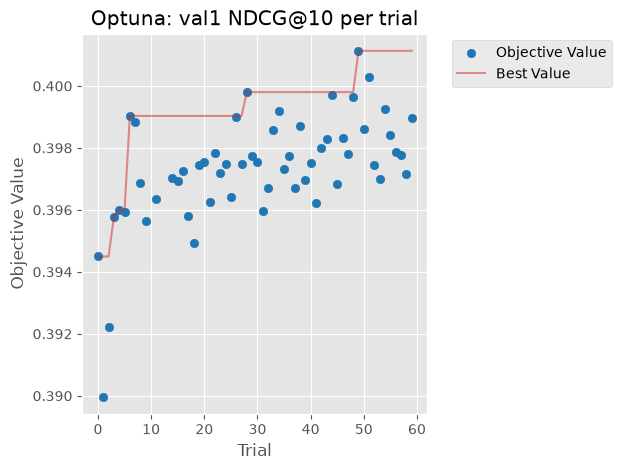

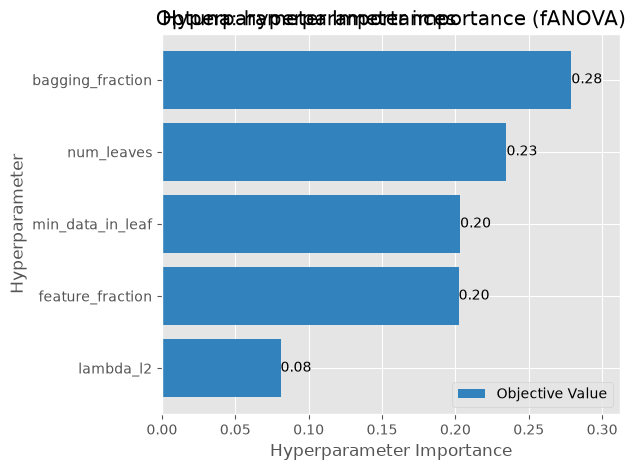

In [11]:
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances

ax = plot_optimization_history(study)
ax.set_title("Optuna: val1 NDCG@10 per trial")
plt.tight_layout(); plt.show()

if sum(t.state == optuna.trial.TrialState.COMPLETE for t in study.trials) >= 3:
    ax = plot_param_importances(study)
    ax.set_title("Optuna: hyperparameter importance (fANOVA)")
    plt.tight_layout(); plt.show()

## 5. Re-check the best trials with 3 seeds
Each trial in the search used one seed, so its score includes some training noise and the "best" trial may be partly lucky. The top trials and the untuned ablation model are retrained with 3 seeds. Each configuration's per-slate scores are averaged over seeds and compared with the best configuration by a paired bootstrap over val1 slates.

**Choice rule:** among the tuned configurations whose interval against the best includes 0 (within noise), take the simplest one: fewest leaves, then the largest `min_data_in_leaf`, then the largest `lambda_l2`. Its 3 seed models are the final ensemble.

In [12]:
completed = sorted([t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE],
                   key=lambda t: t.value, reverse=True)
candidates = {f"trial {t.number}": {"learning_rate": LEARNING_RATE, **t.params} for t in completed[:TOP_K_RECHECK]}
candidates["untuned reference"] = dict(REFERENCE_PARAMS)

recheck = {}
for name, params in candidates.items():
    t0 = time.time()
    models = [train(params, seed=s) for s in SEEDS]
    tables = [val1_metrics(m) for m in models]
    recheck[name] = {"params": params, "models": models, "per_slate": seed_avg(tables),
                     "per_seed": [t["ndcg@10"].mean() for t in tables],
                     "trees": [int(m.best_iteration) for m in models]}
    print(f"{name}: ndcg@10 per seed {np.round(recheck[name]['per_seed'], 4)} | {time.time() - t0:.0f}s")

trial 49: ndcg@10 per seed [0.4011 0.3981 0.4021] | 31s
trial 51: ndcg@10 per seed [0.4003 0.3975 0.401 ] | 24s
trial 28: ndcg@10 per seed [0.3998 0.3999 0.3992] | 25s
trial 44: ndcg@10 per seed [0.3997 0.3974 0.4011] | 30s
trial 48: ndcg@10 per seed [0.3996 0.3975 0.4006] | 29s
untuned reference: ndcg@10 per seed [0.394  0.395  0.3966] | 17s


In [13]:
tuned = [n for n in recheck if n != "untuned reference"]
best_name = max(tuned, key=lambda n: recheck[n]["per_slate"]["ndcg@10"].mean())

rows = []
for name, r in recheck.items():
    d = paired_diff(r["per_slate"], recheck[best_name]["per_slate"])
    p = r["params"]
    rows.append({"configuration": name, "ndcg@10 (3-seed avg)": r["per_slate"]["ndcg@10"].mean(),
                 "seed_sd": np.std(r["per_seed"]), "hit@10": r["per_slate"]["hit@10"].mean(),
                 "mrr": r["per_slate"]["mrr"].mean(), "mean_trees": np.mean(r["trees"]),
                 "num_leaves": p["num_leaves"], "min_data_in_leaf": p["min_data_in_leaf"], "lambda_l2": p["lambda_l2"],
                 "diff_vs_best": d["diff"], "ci_low": d["ci_low"], "ci_high": d["ci_high"],
                 "within_noise": bool(d["ci_low"] <= 0 <= d["ci_high"]) or name == best_name})
recheck_table = pd.DataFrame(rows).set_index("configuration")
print(recheck_table.round(4).to_string())

eligible = recheck_table.loc[tuned].query("within_noise")
chosen_name = eligible.sort_values(["num_leaves", "min_data_in_leaf", "lambda_l2"],
                                   ascending=[True, False, False]).index[0]
chosen = recheck[chosen_name]
final_models = chosen["models"]
final_params = chosen["params"]
print(f"\nbest: {best_name} | chosen (simplest within noise): {chosen_name}")
print("chosen parameters:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in final_params.items()})
print("trees per seed:", chosen["trees"])

ens_val1 = val1_metrics(final_models)
ref_val1 = val1_metrics(recheck["untuned reference"]["models"])
d = paired_diff(ens_val1, ref_val1)
print(f"\nval1 NDCG@10, 3-seed ensemble: chosen {ens_val1['ndcg@10'].mean():.4f} vs untuned reference "
      f"{ref_val1['ndcg@10'].mean():.4f} | diff {d['diff']:+.4f} (95% CI {d['ci_low']:+.4f} to {d['ci_high']:+.4f})")
print("Note: val1 was used for tuning and model choice, so these val1 scores are optimistic; "
      "the unbiased estimate comes from the final test evaluation of the blend.")

for name in recheck:                      # free models that are no longer needed
    if name not in (chosen_name, "untuned reference"):
        recheck[name]["models"] = None

                   ndcg@10 (3-seed avg)  seed_sd  hit@10     mrr  mean_trees  num_leaves  min_data_in_leaf  lambda_l2  diff_vs_best  ci_low  ci_high  within_noise
configuration                                                                                                                                                     
trial 49                         0.4004   0.0017  0.6434  0.3457     17.6667         251                87     0.1695        0.0000  0.0000   0.0000          True
trial 51                         0.3996   0.0015  0.6436  0.3444     15.0000         173                57     0.0132       -0.0008 -0.0030   0.0012          True
trial 28                         0.3996   0.0003  0.6436  0.3443     17.3333         192               110     0.1889       -0.0008 -0.0031   0.0014          True
trial 44                         0.3994   0.0015  0.6418  0.3448     21.0000         232                77     0.0121       -0.0010 -0.0035   0.0015          True
trial 48              

## 6. Final model and scores for the next step
The final Model 1 is the **average log-odds of the chosen configuration's 3 seed models**, each at its own early-stopped number of trees. Averaging seeds removes part of the training noise measured by `seed_sd` above.

The ensemble score is a ranking score, not a probability. val2 and test are **scored only** here (no labels are read). Section 8b then Platt-scales the score into P1 on val2; the gate notebook (`step5_gate_and_evaluation.ipynb`) fits the gate on val2 and evaluates the blend once on test.

In [14]:
val2_raw = ensemble_raw(final_models, val2)
test_raw = ensemble_raw(final_models, test)
print(f"ensemble scores computed for val2 ({len(val2_raw):,} rows) and test ({len(test_raw):,} rows)")

ensemble scores computed for val2 (1,511,179 rows) and test (1,500,706 rows)


## 7. Explainability
Two views of what the final ensemble uses, averaged over its 3 seed models:
- **Gain importance:** how much each feature improved the training loss. Correlated features split the credit (as raw and log popularity did in the ablation), so read this together with the ablation results.
- **SHAP values** (LightGBM's built-in TreeSHAP, `pred_contrib`) on a random sample of val1 rows: the mean absolute contribution of each feature to the log-odds score. SHAP describes the model, not its accuracy, so it does not need test.

                            gain_%  mean_abs_shap          group
candidate_log_popularity   43.5444         0.1731     popularity
candidate_log_pop_cart     22.8370         0.0772     popularity
candidate_log_pop_ord      10.8537         0.0515     popularity
query_candidate_name_sim    3.6349         0.0397     similarity
query_candidate_cate4_sim   1.0813         0.0187     similarity
current_query_length        0.8322         0.0164        context
item_click_cnt_7d           9.1768         0.0128   item_history
brand_days_since_cart       0.6500         0.0061  brand_history
brand_days_since_ord        0.4053         0.0050  brand_history
item_days_since_cart        2.8297         0.0031   item_history
item_cart_cnt_90d           2.3329         0.0028   item_history
brand_click_cnt_7d          0.3644         0.0025  brand_history
brand_ord_cnt_365d          0.1558         0.0016  brand_history
brand_cart_cnt_90d          0.1685         0.0009  brand_history
item_ord_cnt_365d        

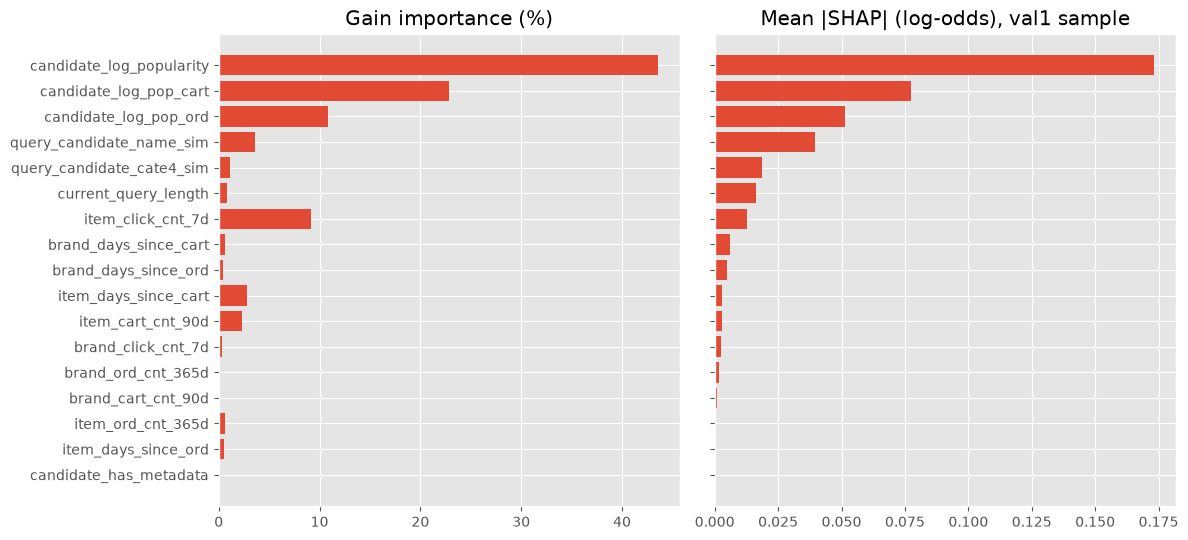

In [15]:
gain = pd.DataFrame({s: pd.Series(m.feature_importance("gain", iteration=m.best_iteration), index=FINAL_FEATURES)
                     for s, m in zip(SEEDS, final_models)}).mean(axis=1)
gain_pct = (100 * gain / gain.sum())

rng = np.random.default_rng(SEED)
idx = rng.choice(len(val1), size=min(SHAP_ROWS, len(val1)), replace=False)
X = val1.iloc[np.sort(idx)][FINAL_FEATURES]
contrib = np.mean([m.predict(X, num_iteration=m.best_iteration, pred_contrib=True, num_threads=THREADS)
                   for m in final_models], axis=0)
shap_abs = pd.Series(np.abs(contrib[:, :-1]).mean(axis=0), index=FINAL_FEATURES)   # last column is the bias

imp = pd.DataFrame({"gain_%": gain_pct, "mean_abs_shap": shap_abs,
                    "group": [FEATURE_GROUP[f] for f in FINAL_FEATURES]}).sort_values("mean_abs_shap", ascending=False)
print(imp.round(4).to_string())
print("\nby group, gain %:", imp.groupby("group")["gain_%"].sum().round(1).sort_values(ascending=False).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
order = imp.index[::-1]
axes[0].barh(order, imp.loc[order, "gain_%"]); axes[0].set_title("Gain importance (%)")
axes[1].barh(order, imp.loc[order, "mean_abs_shap"]); axes[1].set_title("Mean |SHAP| (log-odds), val1 sample")
plt.tight_layout(); plt.show()

## 8. Save the models and scores
- `model1_seed{s}.txt`: the 3 LightGBM models, each saved at its best iteration (reload with `lgb.Booster(model_file=...)`).
- `model1_config.json`: features, chosen parameters, trees per seed and the val1 results.
- `model1_scores_{val2,test}.parquet`: one row per (slate, candidate) with `slate_id`, `wid`, `label` and `raw_score` (the ensemble's mean log-odds), ready to join with Model 2's scores and the gate features on `slate_id`, `wid`. Section 8b adds the calibrated `p1` column to both files.

To score new rows: average `predict(X, raw_score=True)` over the 3 models.

In [16]:
for s, m in zip(SEEDS, final_models):
    m.save_model(str(OUT / f"model1_seed{s}.txt"), num_iteration=m.best_iteration)

config = {
    "features": FINAL_FEATURES,
    "objective": "binary on any interaction, sample weights " + json.dumps({str(k): v for k, v in GRADED_WEIGHT.items()}),
    "params": {k: (float(v) if isinstance(v, (float, np.floating)) else int(v) if isinstance(v, (int, np.integer)) else v)
               for k, v in final_params.items()},
    "chosen_trial": chosen_name,
    "seeds": SEEDS,
    "trees_per_seed": chosen["trees"],
    "ensemble": "mean of raw (log-odds) scores of the seed models",
    "optuna": {"study": STUDY_NAME, "trials": int(len(study.trials)), "best_trial": int(study.best_trial.number),
               "best_val1_ndcg@10_single_seed": float(study.best_value)},
    "val1_ndcg@10": {"model1_ensemble": float(ens_val1["ndcg@10"].mean()),
                     "untuned_reference_ensemble": float(ref_val1["ndcg@10"].mean())},
}
with open(OUT / "model1_config.json", "w") as fh:
    json.dump(config, fh, indent=2)

for name, df, raw in [("val2", val2, val2_raw), ("test", test, test_raw)]:
    out = df[["slate_id", "wid", "label"]].assign(raw_score=raw.astype(np.float32))
    out.to_parquet(OUT / f"model1_scores_{name}.parquet", index=False)

print("saved to", OUT.resolve())
for f in sorted(OUT.iterdir()):
    print(f"  {f.name:30s} {f.stat().st_size / 1e6:8.2f} MB")

saved to /Users/mabel/Documents/NUS_Mabel/Year 4/Y4S1/BT4222/bt4222-grp8/models/model1
  .DS_Store                          0.01 MB
  model1_config.json                 0.00 MB
  model1_scores_test.parquet        14.41 MB
  model1_scores_val2.parquet        14.51 MB
  model1_seed0.txt                   0.35 MB
  model1_seed1.txt                   0.35 MB
  model1_seed2.txt                   0.17 MB


## 8b. Calibration: Platt scaling on val2 (P1)
Model 1's raw score is the log-odds of *any interaction*, learned on negative-sampled training data, so it is not a purchase probability. Platt scaling fits `P1 = sigmoid(a · raw_score + b)` against the purchase label (label 3) on **all val2 candidates**. This is the same method and the same split as Model 2's calibration (`step4_model2_din`, Step 8), so P1 and P2 are on the same scale for the gate. val2 was not used for tuning or model choice. Platt scaling is strictly increasing, so it does not change Model 1's ranking within a search.

**Saved:** `calibration.json` (`a`, `b`), and a `p1` column added to `model1_scores_{val2,test}.parquet`. Test labels are read only to print the calibration check; nothing is fitted on test.

The cell reads the saved score files, so after a restart it can run on its own: run the two setup cells in section 0, then this cell. No retraining needed.

In [ ]:
# 8b. Platt scaling on val2: same method as Model 2 (step4_model2_din, Step 8)
from sklearn.linear_model import LogisticRegression

CALIB_SPLIT = "val2"


def fit_platt(logit, label):
    lr = LogisticRegression(C=1e6, max_iter=1000)
    lr.fit(logit.reshape(-1, 1), (label == 3).astype(int))
    return float(lr.coef_[0, 0]), float(lr.intercept_[0])


def apply_platt(logit, a, b):
    return 1.0 / (1.0 + np.exp(-np.clip(a * logit + b, -50, 50)))


# read the files saved in section 8 (ignore_metadata avoids the pandas/pyarrow metadata TypeError)
scores = {s: pq.read_table(OUT / f"model1_scores_{s}.parquet").to_pandas(ignore_metadata=True)
          for s in [CALIB_SPLIT, "test"]}
A, B = fit_platt(scores[CALIB_SPLIT]["raw_score"].to_numpy(np.float64),
                 scores[CALIB_SPLIT]["label"].to_numpy())
(OUT / "calibration.json").write_text(json.dumps({"method": "platt", "a": A, "b": B, "fitted_on": CALIB_SPLIT}, indent=2))

for split, df in scores.items():
    df["p1"] = apply_platt(df["raw_score"].to_numpy(np.float64), A, B)
    df.to_parquet(OUT / f"model1_scores_{split}.parquet", index=False)
    print(f"{split}: mean P1 {df['p1'].mean():.5f} vs purchase rate {df['label'].eq(3).mean():.5f} "
          f"(calibrated on {CALIB_SPLIT}: these should be close there)")
print(f"Platt: a = {A:.4f}, b = {B:.4f} | saved calibration.json and p1 in model1_scores_{{val2,test}}.parquet")

## 8c. Train-set scores for the evaluation

Sections 6 and 8 save scores for val2 and test only. The evaluation in `step5_gate_and_evaluation.ipynb` also compares the models on the **train set**,

In [ ]:
# train scores (only searches with a purchase), from the saved models
cal1 = json.loads((OUT / "calibration.json").read_text())
train_s = pd.read_parquet(FEAT / "features_train.parquet", columns=["slate_id", "wid", "label"] + FINAL_FEATURES)
boosters = [lgb.Booster(model_file=str(OUT / f"model1_seed{s}.txt")) for s in SEEDS]
train_s["raw_score"] = np.mean([b.predict(train_s[FINAL_FEATURES], raw_score=True) for b in boosters], axis=0)
train_s["p1"] = 1.0 / (1.0 + np.exp(-np.clip(cal1["a"] * train_s["raw_score"] + cal1["b"], -50, 50)))
has_purchase = train_s["label"].eq(3).groupby(train_s["slate_id"]).transform("any")
train_s = train_s.loc[has_purchase, ["slate_id", "wid", "label", "raw_score", "p1"]].reset_index(drop=True)
train_s.to_parquet(OUT / "model1_scores_train.parquet", index=False)
print(f"saved model1_scores_train.parquet: {train_s['slate_id'].nunique():,} searches, {len(train_s):,} rows")

## 9. Summary
The cell below prints the headline numbers of the final Model 1 (val1, optimistic because it was used for tuning). P1 is blended with Model 2 in `step5_gate_and_evaluation.ipynb`.

In [17]:
print(f"Model 1 (LightGBM, {len(FINAL_FEATURES)} features, {chosen_name}, 3-seed ensemble)")
print(f"  val1 NDCG@10 {ens_val1['ndcg@10'].mean():.4f} | HitRate@10 {ens_val1['hit@10'].mean():.4f} | "
      f"HitRate@1 {ens_val1['hit@1'].mean():.4f} | MRR {ens_val1['mrr'].mean():.4f}")
print(f"  untuned reference val1 NDCG@10 {ref_val1['ndcg@10'].mean():.4f}")
print("  trees per seed:", chosen["trees"])

Model 1 (LightGBM, 17 features, trial 51, 3-seed ensemble)
  val1 NDCG@10 0.3993 | HitRate@10 0.6438 | HitRate@1 0.2056 | MRR 0.3441
  untuned reference val1 NDCG@10 0.3957
  trees per seed: [18, 18, 9]


## 10. Experiments (val1 only, nothing saved)
These checks explain the val1 result. They do **not** change the chosen model or the files saved in section 8, use only val1, and write nothing to disk.

### 10.1 Training objective
Early stopping kept only about 10–20 trees at learning rate 0.05, which suggests that extra trees fit the training target but not purchase ranking. Two possible causes are tested by changing only the objective:
- **graded binary (chosen):** any interaction, sample weights click 1 / cart 5 / purchase 10.
- **purchase-only binary:** target = purchase, no weights, so clicks and carts count as negatives.
- **LambdaRank, graded:** learns the ranking within each slate directly, with gains click 1, cart 3, purchase 7 (LightGBM's default `2^label − 1`).
- **LambdaRank, purchase-only:** the same, with only purchases relevant.

Each uses the **chosen hyperparameters** (tuned for the graded binary objective, so the others may be slightly disadvantaged), 3 seeds, and early stopping on val1 NDCG@10, as in section 5. Per-slate scores are averaged over seeds and compared with the chosen objective by a paired bootstrap over val1 purchase slates.

In [18]:
OBJECTIVES = {
    "graded binary (chosen)":    {"objective": "binary",     "label": lambda l: l >= 1, "weight": GRADED_WEIGHT},
    "purchase-only binary":      {"objective": "binary",     "label": lambda l: l == 3, "weight": None},
    "LambdaRank, graded":        {"objective": "lambdarank", "label": lambda l: l,      "weight": None},
    "LambdaRank, purchase-only": {"objective": "lambdarank", "label": lambda l: l == 3, "weight": None},
}


def train_objective(spec, params, seed):
    # same as train(), with the objective, target and weights replaced
    lab = fit["label"].to_numpy()
    w = None if spec["weight"] is None else fit["label"].map(spec["weight"]).to_numpy(dtype=np.float64)
    d_tr = lgb.Dataset(fit[FINAL_FEATURES], label=spec["label"](lab).astype(np.int8), weight=w,
                       group=slate_sizes(fit), params=DATASET_PARAMS, free_raw_data=False)
    d_va = lgb.Dataset(val1_p[FINAL_FEATURES], label=val1_p["label"].eq(3).astype(np.int8).to_numpy(),
                       group=slate_sizes(val1_p), reference=d_tr, free_raw_data=False)
    p = {**BASE_PARAMS, **params, "objective": spec["objective"], "bagging_seed": seed, "feature_fraction_seed": seed}
    return lgb.train(p, d_tr, MAX_ROUNDS, valid_sets=[d_va], valid_names=["val1"],
                     callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False)])


obj_runs = {"graded binary (chosen)": {"per_slate": chosen["per_slate"], "per_seed": chosen["per_seed"],
                                       "trees": chosen["trees"]}}          # already trained in section 5
for name, spec in OBJECTIVES.items():
    if name in obj_runs:
        continue
    t0 = time.time()
    models = [train_objective(spec, final_params, s) for s in SEEDS]
    tables = [val1_metrics(m) for m in models]
    obj_runs[name] = {"per_slate": seed_avg(tables), "per_seed": [t["ndcg@10"].mean() for t in tables],
                      "trees": [int(m.best_iteration) for m in models]}
    print(f"{name}: ndcg@10 per seed {np.round(obj_runs[name]['per_seed'], 4)} | "
          f"trees {obj_runs[name]['trees']} | {time.time() - t0:.0f}s")
    del models

rows = []
for name, r in obj_runs.items():
    d = paired_diff(r["per_slate"], obj_runs["graded binary (chosen)"]["per_slate"])
    rows.append({"objective": name, "ndcg@10 (3-seed avg)": r["per_slate"]["ndcg@10"].mean(),
                 "seed_sd": np.std(r["per_seed"]), "hit@10": r["per_slate"]["hit@10"].mean(),
                 "mrr": r["per_slate"]["mrr"].mean(), "mean_trees": np.mean(r["trees"]),
                 "diff_vs_chosen": d["diff"], "ci_low": d["ci_low"], "ci_high": d["ci_high"]})
print("\n" + pd.DataFrame(rows).set_index("objective").round(4).to_string())

purchase-only binary: ndcg@10 per seed [0.3643 0.3695 0.3722] | trees [32, 23, 21] | 24s
LambdaRank, graded: ndcg@10 per seed [0.404  0.4015 0.4011] | trees [203, 281, 119] | 64s
LambdaRank, purchase-only: ndcg@10 per seed [0.3918 0.3898 0.3905] | trees [111, 100, 28] | 37s

                           ndcg@10 (3-seed avg)  seed_sd  hit@10     mrr  mean_trees  diff_vs_chosen  ci_low  ci_high
objective                                                                                                            
graded binary (chosen)                   0.3996   0.0015  0.6436  0.3444     15.0000          0.0000  0.0000   0.0000
purchase-only binary                     0.3687   0.0033  0.6087  0.3162     25.3333         -0.0310 -0.0380  -0.0242
LambdaRank, graded                       0.4022   0.0013  0.6432  0.3479    201.0000          0.0026 -0.0021   0.0073
LambdaRank, purchase-only                0.3907   0.0008  0.6315  0.3367     79.6667         -0.0089 -0.0142  -0.0037


**How to read it:** an objective is better only if its interval against the chosen one lies entirely above 0. `mean_trees` shows whether a different objective lets the model use more trees before val1 NDCG@10 stops improving. If an objective clearly wins, the next step would be to re-tune it with Optuna (section 4) before switching; this section does not change the saved model.

### 10.2 Performance by history length
If sparse personal history limits Model 1, its gain over popularity should grow with the user's history length. val1 purchase slates are grouped by history length, in the same buckets used to stratify the split, and Model 1 (the saved 3-seed ensemble) is compared with popularity alone and random order in each bucket. History lengths are read from `step1/val1.parquet` (one column).

val1 NDCG@10 by history length (purchase slates):
                slates  model1  popularity_only  random  model1_minus_pop  ci_low  ci_high
history_length                                                                            
0-29               450  0.3685           0.3236  0.0685            0.0450  0.0251   0.0665
30-78              472  0.3932           0.3596  0.0658            0.0336  0.0133   0.0538
79-188             528  0.4198           0.3674  0.0648            0.0524  0.0339   0.0718
189+               495  0.4113           0.3501  0.0717            0.0612  0.0391   0.0831


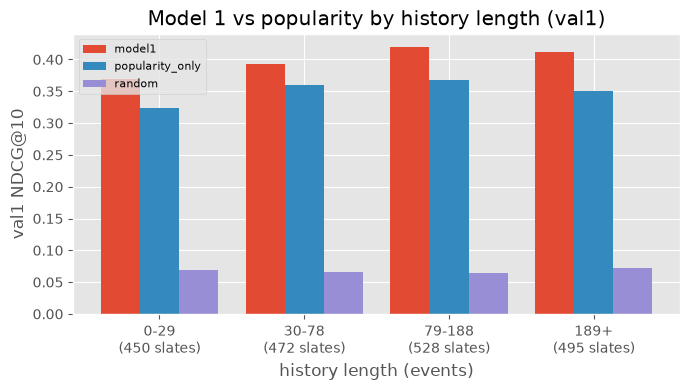

In [ ]:
DATA = PROJECT / "step1"
h = load(DATA / "val1.parquet", columns=["slate_id", "history_wid_list"])
hist_len = pd.Series(h["history_wid_list"].map(len).to_numpy(), index=h["slate_id"].to_numpy())
del h

scored = val1_p[["slate_id", "label"]].assign(
    model1=ensemble_raw(final_models, val1_p), popularity_only=val1_p["candidate_log_popularity"].to_numpy(), random=0.0)
HL_METHODS = ["model1", "popularity_only", "random"]
ps_hl = {m: per_slate_metrics(scored, m) for m in HL_METHODS}

seg = ps_hl["model1"][["slate_id"]].copy()
for m in HL_METHODS:
    seg[m] = ps_hl[m]["ndcg@10"].to_numpy()
seg["history_length"] = pd.cut(seg["slate_id"].map(hist_len), bins=[0, 29, 78, 188, np.inf], include_lowest=True,
                               labels=["0-29", "30-78", "79-188", "189+"])
assert seg["history_length"].notna().all(), "some val1 slates have no history length"

hl = seg.groupby("history_length", observed=True)[HL_METHODS].mean()
hl.insert(0, "slates", seg.groupby("history_length", observed=True).size())
for b in hl.index:                       # Model 1 minus popularity within the bucket, paired bootstrap
    s = seg[seg["history_length"] == b]
    d = paired_diff(ps_hl["model1"][ps_hl["model1"]["slate_id"].isin(s["slate_id"])].reset_index(drop=True),
                    ps_hl["popularity_only"][ps_hl["popularity_only"]["slate_id"].isin(s["slate_id"])].reset_index(drop=True))
    hl.loc[b, ["model1_minus_pop", "ci_low", "ci_high"]] = [d["diff"], d["ci_low"], d["ci_high"]]
print("val1 NDCG@10 by history length (purchase slates):")
print(hl.round(4).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(hl))
for k, m in enumerate(HL_METHODS):
    ax.bar(x + (k - 1) * 0.27, hl[m], width=0.27, label=m)
ax.set_xticks(x, [f"{b}\n({n} slates)" for b, n in zip(hl.index, hl["slates"])])
ax.set_xlabel("history length (events)"); ax.set_ylabel("val1 NDCG@10")
ax.set_title("Model 1 vs popularity by history length (val1)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**How to read it:** if `model1_minus_pop` grows with history length, Model 1's personal-history features add value only when there is history to use, so its ceiling comes from sparse history, which Model 2 and the gate are meant to address. Buckets have only a few hundred purchase slates each, so check the intervals before reading differences between buckets.